# Experiment 16: LLM Application Deployment and Response Evaluation

## Aim
To evaluate an LLM application and prepare reproducible deployment documentation.

## Brief Theory
Deployment evaluation considers model quality and operational behavior, including inference latency, reliability, usability, and reproducibility. A controlled test set and an explicit evaluation rubric make comparisons more meaningful.

In [1]:
!pip -q install -U transformers sentencepiece pandas matplotlib seaborn

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.


In [2]:
import os
import json
import time
import platform
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
from IPython.display import display

STUDENT_NAME = "Abu Sayem"
STUDENT_ID = "25/SET/MTCE/014"
MODEL_NAME = "google/flan-t5-small"

print("Student Name:", STUDENT_NAME)
print("Student ID:", STUDENT_ID)
print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Student Name: Abu Sayem
Student ID: 25/SET/MTCE/014
Python: 3.13.18
PyTorch: 2.14.1+cpu
CUDA available: False


In [3]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)
model.eval()

print("Model loaded successfully!")
print("Model:", MODEL_NAME)
print("Device:", device)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

... (3 outputs left out)

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

Model loaded successfully!
Model: google/flan-t5-small
Device: cpu


In [4]:
def generate_response(prompt, max_new_tokens=100):
    prompt = str(prompt).strip()
    if not prompt:
        raise ValueError("Prompt cannot be empty.")

    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=512
    )
    inputs = {key: value.to(device) for key, value in inputs.items()}

    if device.type == "cuda":
        torch.cuda.synchronize()

    start_time = time.perf_counter()

    with torch.inference_mode():
        output_ids = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False
        )

    if device.type == "cuda":
        torch.cuda.synchronize()

    latency = time.perf_counter() - start_time
    response = tokenizer.decode(output_ids[0], skip_special_tokens=True)

    return response, latency

print("Generation function is ready.")

Generation function is ready.


In [5]:
sample_prompt = "Explain Artificial Intelligence in simple words."
sample_response, sample_latency = generate_response(sample_prompt)

print("Prompt:", sample_prompt)
print("\nResponse:", sample_response)
print(f"\nLatency: {sample_latency:.4f} seconds")

Prompt: Explain Artificial Intelligence in simple words.

Response: Artificial intelligence is the ability to understand the world.

Latency: 0.6118 seconds


In [6]:
test_prompts = [
    "Explain Artificial Intelligence in simple words.",
    "What is Machine Learning?",
    "Explain the difference between Artificial Intelligence and Machine Learning.",
    "What are the main types of Machine Learning?",
    "What is Deep Learning?",
    "Explain the role of neural networks in Deep Learning.",
    "What is Natural Language Processing?",
    "Give three real-world applications of Natural Language Processing.",
    "What is Generative AI?",
    "Explain the difference between supervised and unsupervised learning."
]

print("Total test prompts:", len(test_prompts))
for i, prompt in enumerate(test_prompts, start=1):
    print(f"{i}. {prompt}")

Total test prompts: 10
1. Explain Artificial Intelligence in simple words.
2. What is Machine Learning?
3. Explain the difference between Artificial Intelligence and Machine Learning.
4. What are the main types of Machine Learning?
5. What is Deep Learning?
6. Explain the role of neural networks in Deep Learning.
7. What is Natural Language Processing?
8. Give three real-world applications of Natural Language Processing.
9. What is Generative AI?
10. Explain the difference between supervised and unsupervised learning.


In [7]:
results = []

for test_no, prompt in enumerate(test_prompts, start=1):
    print(f"Running test {test_no}/{len(test_prompts)} ...")
    try:
        response, latency = generate_response(prompt, max_new_tokens=100)
        results.append({
            "Test No": test_no,
            "Prompt": prompt,
            "Response": response,
            "Latency (seconds)": latency,
            "Response Length (characters)": len(response),
            "Status": "Success",
            "Error": ""
        })
    except Exception as exc:
        results.append({
            "Test No": test_no,
            "Prompt": prompt,
            "Response": "",
            "Latency (seconds)": np.nan,
            "Response Length (characters)": 0,
            "Status": "Failed",
            "Error": str(exc)
        })

results_df = pd.DataFrame(results)
display(results_df)

Running test 1/10 ...
Running test 2/10 ...
Running test 3/10 ...
Running test 4/10 ...
Running test 5/10 ...
Running test 6/10 ...
Running test 7/10 ...
Running test 8/10 ...
Running test 9/10 ...
Running test 10/10 ...


,Test No,Prompt,Response,Latency (seconds),Response Length (characters),Status,Error
0,1,Explain Artificial Intelligence in simple words.,Artificial intelligence is the ability to unde...,0.473757,63,Success,
1,2,What is Machine Learning?,Machine learning is a process of learning to l...,0.650153,51,Success,
2,3,Explain the difference between Artificial Inte...,Artificial Intelligence (AI) is a technology t...,2.304794,105,Success,
3,4,What are the main types of Machine Learning?,arithmetic,0.396355,10,Success,
4,5,What is Deep Learning?,Deep learning is a learning tool used to learn...,2.258080,157,Success,
5,6,Explain the role of neural networks in Deep Le...,Deep learning is a process that requires a neu...,2.696557,125,Success,
6,7,What is Natural Language Processing?,Natural language processing,0.552874,27,Success,
7,8,Give three real-world applications of Natural ...,"Using a cellular phone, a computer is able to ...",1.611340,74,Success,
8,9,What is Generative AI?,a generative AI,0.235412,15,Success,
9,10,Explain the difference between supervised and ...,supervised learning is a learning process that...,0.412252,74,Success,


In [8]:
successful_results = results_df[results_df["Status"] == "Success"].copy()
latencies = successful_results["Latency (seconds)"].dropna()

if len(latencies):
    latency_summary = pd.DataFrame([{
        "Successful Tests": len(latencies),
        "Average Latency (s)": latencies.mean(),
        "Median Latency (s)": latencies.median(),
        "Minimum Latency (s)": latencies.min(),
        "Maximum Latency (s)": latencies.max(),
        "Standard Deviation (s)": latencies.std(ddof=0)
    }])
    display(latency_summary.round(4))
else:
    print("No successful latency measurements are available.")

,Successful Tests,Average Latency (s),Median Latency (s),Minimum Latency (s),Maximum Latency (s),Standard Deviation (s)
0,10,1.1592,0.6015,0.2354,2.6966,0.9043


In [9]:
# Format: Test No: [Relevance, Factuality, Clarity, Usability]
# Replace None with your own scores after reviewing each response.
manual_scores = {
    1: [None, None, None, None],
    2: [None, None, None, None],
    3: [None, None, None, None],
    4: [None, None, None, None],
    5: [None, None, None, None],
    6: [None, None, None, None],
    7: [None, None, None, None],
    8: [None, None, None, None],
    9: [None, None, None, None],
    10: [None, None, None, None]
}

quality_rows = []
for _, row in successful_results.iterrows():
    test_no = int(row["Test No"])
    scores = manual_scores.get(test_no, [None, None, None, None])

    if any(score is None for score in scores):
        continue
    if not all(isinstance(score, (int, np.integer)) and 1 <= score <= 5 for score in scores):
        raise ValueError(f"Test {test_no}: enter four integer scores between 1 and 5.")

    total = sum(scores)
    quality_rows.append({
        "Test No": test_no,
        "Relevance": scores[0],
        "Factuality": scores[1],
        "Clarity": scores[2],
        "Usability": scores[3],
        "Total Score (out of 20)": total,
        "Quality Percentage": total / 20 * 100
    })

quality_df = pd.DataFrame(quality_rows)
if len(quality_df):
    display(quality_df)
    print(f"Scored responses: {len(quality_df)}")
else:
    print("No quality scores entered yet. Edit manual_scores above, then rerun this cell.")

No quality scores entered yet. Edit manual_scores above, then rerun this cell.


In [10]:
if len(quality_df):
    quality_summary = quality_df[[
        "Relevance", "Factuality", "Clarity", "Usability"
    ]].mean().to_frame("Average Score (out of 5)")
    display(quality_summary.round(2))
    overall_quality = quality_df["Quality Percentage"].mean()
    print(f"Overall average quality: {overall_quality:.2f}%")
else:
    print("Enter manual scores in Part 10 before calculating quality summary.")

Enter manual scores in Part 10 before calculating quality summary.


In [11]:
failure_rows = []

for _, row in results_df[results_df["Status"] != "Success"].iterrows():
    failure_rows.append({
        "Test No": row["Test No"],
        "Issue Type": "Technical failure",
        "Description": row["Error"]
    })

# Optional manual issue review. Leave as 'none' if no issue is identified.
# Edit values after inspecting the responses.
manual_issues = {
    # Example format:
    # 3: ("Unsupported claim", "Response included a claim not supported by reliable evidence.")
}

for test_no, issue in manual_issues.items():
    issue_type, description = issue
    failure_rows.append({
        "Test No": test_no,
        "Issue Type": issue_type,
        "Description": description
    })

failure_df = pd.DataFrame(
    failure_rows,
    columns=["Test No", "Issue Type", "Description"]
)

print("Recorded issues:", len(failure_df))
display(failure_df)

Recorded issues: 0


,Test No,Issue Type,Description


In [12]:
comparison_prompts = test_prompts[:5]
comparison_rows = []

for test_no, prompt in enumerate(comparison_prompts, start=1):
    enhanced_prompt = (
        "Answer the following question clearly and accurately "
        "using simple language: " + prompt
    )

    try:
        response_a, latency_a = generate_response(prompt, max_new_tokens=100)
        response_b, latency_b = generate_response(enhanced_prompt, max_new_tokens=100)

        comparison_rows.append({
            "Test No": test_no,
            "Original Prompt": prompt,
            "Response A": response_a,
            "Latency A (s)": latency_a,
            "Enhanced Prompt": enhanced_prompt,
            "Response B": response_b,
            "Latency B (s)": latency_b,
            "Status": "Success"
        })
    except Exception as exc:
        comparison_rows.append({
            "Test No": test_no,
            "Original Prompt": prompt,
            "Response A": "",
            "Latency A (s)": np.nan,
            "Enhanced Prompt": enhanced_prompt,
            "Response B": "",
            "Latency B (s)": np.nan,
            "Status": f"Failed: {exc}"
        })

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df)

,Test No,Original Prompt,Response A,Latency A (s),Enhanced Prompt,Response B,Latency B (s),Status
0,1,Explain Artificial Intelligence in simple words.,Artificial intelligence is the ability to unde...,0.310243,Answer the following question clearly and accu...,a symbiosis of artificial intelligence,0.365471,Success
1,2,What is Machine Learning?,Machine learning is a process of learning to l...,0.346792,Answer the following question clearly and accu...,Machine learning,0.108589,Success
2,3,Explain the difference between Artificial Inte...,Artificial Intelligence (AI) is a technology t...,0.570910,Answer the following question clearly and accu...,Artificial Intelligence (AI) is a technology t...,0.594831,Success
3,4,What are the main types of Machine Learning?,arithmetic,0.179160,Answer the following question clearly and accu...,arithmetic,0.191370,Success
4,5,What is Deep Learning?,Deep learning is a learning tool used to learn...,1.222977,Answer the following question clearly and accu...,Deep learning,0.155913,Success


In [13]:
valid_comparison = comparison_df[comparison_df["Status"] == "Success"].copy()

if len(valid_comparison):
    avg_latency_a = valid_comparison["Latency A (s)"].mean()
    avg_latency_b = valid_comparison["Latency B (s)"].mean()

    print(f"Configuration A average latency: {avg_latency_a:.4f} seconds")
    print(f"Configuration B average latency: {avg_latency_b:.4f} seconds")
    print("A lower measured latency means faster response in this run.")
    print("Interpret differences cautiously: prompt length and runtime variation affect latency.")
else:
    print("No successful configuration comparisons.")

Configuration A average latency: 0.5260 seconds
Configuration B average latency: 0.2832 seconds
A lower measured latency means faster response in this run.
Interpret differences cautiously: prompt length and runtime variation affect latency.


In [14]:
# Format: Test No: [Configuration A total score, Configuration B total score]
comparison_manual_scores = {
    1: [None, None],
    2: [None, None],
    3: [None, None],
    4: [None, None],
    5: [None, None]
}

comparison_quality_rows = []

for _, row in valid_comparison.iterrows():
    test_no = int(row["Test No"])
    scores = comparison_manual_scores.get(test_no, [None, None])

    if any(score is None for score in scores):
        continue
    if not all(isinstance(score, (int, np.integer)) and 0 <= score <= 20 for score in scores):
        raise ValueError(f"Test {test_no}: enter two integer scores between 0 and 20.")

    comparison_quality_rows.append({
        "Test No": test_no,
        "Quality A (out of 20)": scores[0],
        "Quality B (out of 20)": scores[1]
    })

comparison_quality_df = pd.DataFrame(comparison_quality_rows)
if len(comparison_quality_df):
    display(comparison_quality_df)
    print("Average A:", comparison_quality_df["Quality A (out of 20)"].mean())
    print("Average B:", comparison_quality_df["Quality B (out of 20)"].mean())
else:
    print("Enter scores in comparison_manual_scores above, then rerun this cell.")

Enter scores in comparison_manual_scores above, then rerun this cell.


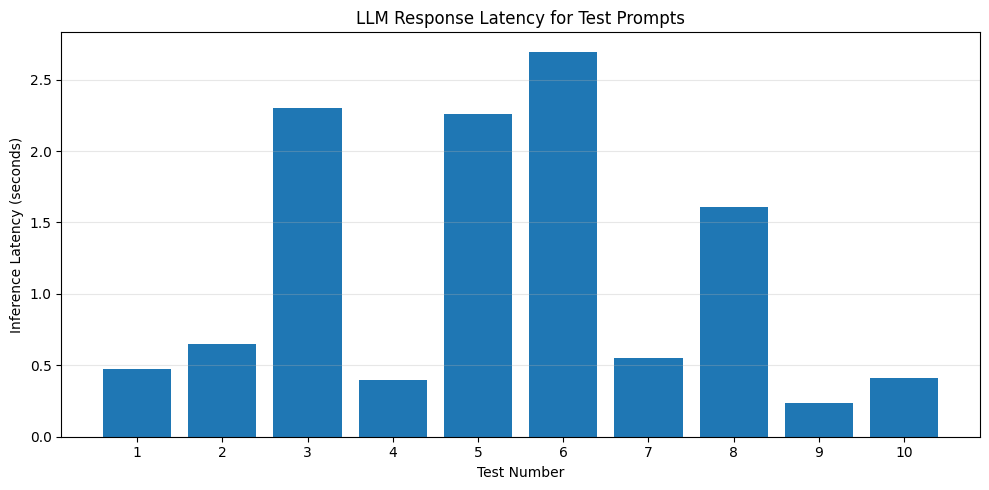

In [15]:
if len(successful_results):
    plt.figure(figsize=(10, 5))
    plt.bar(
        successful_results["Test No"].astype(str),
        successful_results["Latency (seconds)"]
    )
    plt.xlabel("Test Number")
    plt.ylabel("Inference Latency (seconds)")
    plt.title("LLM Response Latency for Test Prompts")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()
else:
    print("No successful tests to plot.")

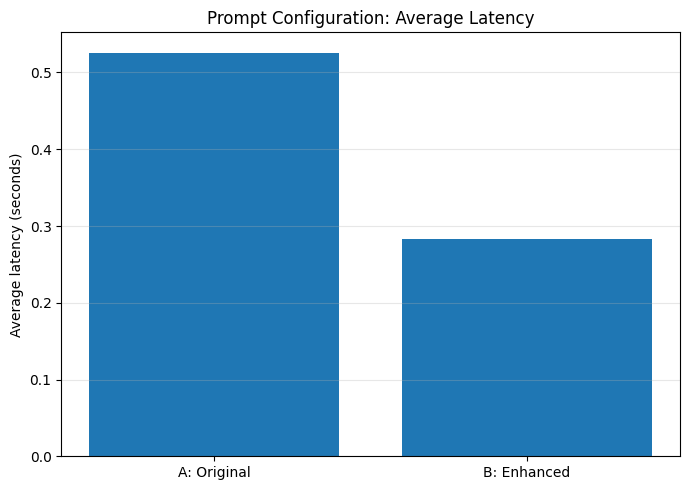

In [16]:
if len(valid_comparison):
    means = [
        valid_comparison["Latency A (s)"].mean(),
        valid_comparison["Latency B (s)"].mean()
    ]
    plt.figure(figsize=(7, 5))
    plt.bar(["A: Original", "B: Enhanced"], means)
    plt.ylabel("Average latency (seconds)")
    plt.title("Prompt Configuration: Average Latency")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()
else:
    print("No comparison data to plot.")

In [17]:
if len(comparison_quality_df):
    quality_means = [
        comparison_quality_df["Quality A (out of 20)"].mean(),
        comparison_quality_df["Quality B (out of 20)"].mean()
    ]
    plt.figure(figsize=(7, 5))
    plt.bar(["A: Original", "B: Enhanced"], quality_means)
    plt.ylabel("Average quality score (out of 20)")
    plt.ylim(0, 20)
    plt.title("Prompt Configuration: Manual Quality Comparison")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()
else:
    print("Enter comparison scores in Part 15 to generate this graph.")

Enter comparison scores in Part 15 to generate this graph.


In [18]:
requirements_text = """torch
transformers
sentencepiece
streamlit
pandas
numpy
matplotlib
"""

with open("requirements.txt", "w", encoding="utf-8") as f:
    f.write(requirements_text)

print("requirements.txt created:")
print(requirements_text)

requirements.txt created:
torch
transformers
sentencepiece
streamlit
pandas
numpy
matplotlib



In [19]:
deployment_config = {
    "project_name": "LLM Web Application",
    "student_name": STUDENT_NAME,
    "student_id": STUDENT_ID,
    "model_name": MODEL_NAME,
    "model_type": "Sequence-to-Sequence",
    "framework": "Hugging Face Transformers",
    "web_framework": "Streamlit",
    "device_used": str(device),
    "max_input_tokens": 512,
    "max_new_tokens": 100,
    "sampling": False,
    "external_api_required": False,
    "evaluation_date": datetime.now().strftime("%Y-%m-%d")
}

with open("deployment_config.json", "w", encoding="utf-8") as f:
    json.dump(deployment_config, f, indent=4)

print(json.dumps(deployment_config, indent=4))

{
    "project_name": "LLM Web Application",
    "student_name": "Abu Sayem",
    "student_id": "25/SET/MTCE/014",
    "model_name": "google/flan-t5-small",
    "model_type": "Sequence-to-Sequence",
    "framework": "Hugging Face Transformers",
    "web_framework": "Streamlit",
    "device_used": "cpu",
    "max_input_tokens": 512,
    "max_new_tokens": 100,
    "sampling": false,
    "external_api_required": false,
    "evaluation_date": "2026-11-09"
}


In [20]:
deployment_guide = f"""
LLM WEB APPLICATION - DEPLOYMENT GUIDE

Student: {STUDENT_NAME}
Student ID: {STUDENT_ID}

1. Install Python 3.10 or 3.11.
2. Create and activate a virtual environment.
3. Install dependencies:
       pip install -r requirements.txt
4. Keep app.py in the project directory.
5. Run the application:
       streamlit run app.py
6. Open the local URL displayed by Streamlit.

MODEL CONFIGURATION
Model: {MODEL_NAME}
Framework: Hugging Face Transformers
Interface: Streamlit
External API key: Not required for this local model setup.

SECURITY AND OPERATIONS
- Do not hard-code secrets or API keys.
- Use environment variables or a secret manager for external API credentials.
- Validate user input and handle exceptions.
- Monitor latency, errors, resource use, and output quality.
- Do not expose sensitive user information in logs.
"""

with open("DEPLOYMENT_GUIDE.txt", "w", encoding="utf-8") as f:
    f.write(deployment_guide.strip())

print(deployment_guide)


LLM WEB APPLICATION - DEPLOYMENT GUIDE

Student: Abu Sayem
Student ID: 25/SET/MTCE/014

1. Install Python 3.10 or 3.11.
2. Create and activate a virtual environment.
3. Install dependencies:
       pip install -r requirements.txt
4. Keep app.py in the project directory.
5. Run the application:
       streamlit run app.py
6. Open the local URL displayed by Streamlit.

MODEL CONFIGURATION
Model: google/flan-t5-small
Framework: Hugging Face Transformers
Interface: Streamlit
External API key: Not required for this local model setup.

SECURITY AND OPERATIONS
- Do not hard-code secrets or API keys.
- Use environment variables or a secret manager for external API credentials.
- Validate user input and handle exceptions.
- Monitor latency, errors, resource use, and output quality.
- Do not expose sensitive user information in logs.



In [21]:
deployment_checklist = {
    "Model downloaded and loaded": model is not None,
    "Ten representative prompts defined": len(test_prompts) == 10,
    "Inference function tested": isinstance(sample_response, str),
    "At least one successful evaluation": len(successful_results) > 0,
    "Latency measured": len(latencies) > 0,
    "Manual quality scoring entered": len(quality_df) > 0,
    "Prompt comparison executed": len(valid_comparison) > 0,
    "Requirements file created": os.path.exists("requirements.txt"),
    "Deployment configuration created": os.path.exists("deployment_config.json"),
    "Deployment guide created": os.path.exists("DEPLOYMENT_GUIDE.txt")
}

for item, passed in deployment_checklist.items():
    print(f"[{'PASS' if passed else 'PENDING'}] {item}")

[PASS] Model downloaded and loaded
[PASS] Ten representative prompts defined
[PASS] Inference function tested
[PASS] At least one successful evaluation
[PASS] Latency measured
[PENDING] Manual quality scoring entered
[PASS] Prompt comparison executed
[PASS] Requirements file created
[PASS] Deployment configuration created
[PASS] Deployment guide created


In [22]:
results_df.to_csv("llm_test_results.csv", index=False)
quality_df.to_csv("llm_quality_evaluation.csv", index=False)
comparison_df.to_csv("configuration_comparison.csv", index=False)
comparison_quality_df.to_csv("configuration_quality_comparison.csv", index=False)
failure_df.to_csv("llm_failure_report.csv", index=False)

print("Evaluation CSV reports saved.")

Evaluation CSV reports saved.


In [23]:
print("=" * 60)
print("LLM APPLICATION EVALUATION REPORT")
print("=" * 60)
print("Student Name:", STUDENT_NAME)
print("Student ID:", STUDENT_ID)
print("Model:", MODEL_NAME)
print("Device:", device)
print("\nTEST SUMMARY")
print("Total prompts:", len(results_df))
print("Successful:", len(successful_results))
print("Failed:", len(results_df) - len(successful_results))

if len(latencies):
    print("\nLATENCY")
    print(f"Average: {latencies.mean():.4f} seconds")
    print(f"Median: {latencies.median():.4f} seconds")

if len(quality_df):
    print("\nQUALITY")
    print(f"Average quality: {quality_df['Quality Percentage'].mean():.2f}%")
else:
    print("\nQUALITY: Manual scores not entered.")

if len(valid_comparison):
    print("\nCONFIGURATION LATENCY")
    print(f"A: {valid_comparison['Latency A (s)'].mean():.4f} seconds")
    print(f"B: {valid_comparison['Latency B (s)'].mean():.4f} seconds")

if len(comparison_quality_df):
    print("\nCONFIGURATION QUALITY")
    print(f"A: {comparison_quality_df['Quality A (out of 20)'].mean():.2f}/20")
    print(f"B: {comparison_quality_df['Quality B (out of 20)'].mean():.2f}/20")

print("\nRecorded issues:", len(failure_df))
print("=" * 60)

LLM APPLICATION EVALUATION REPORT
Student Name: Abu Sayem
Student ID: 25/SET/MTCE/014
Model: google/flan-t5-small
Device: cpu

TEST SUMMARY
Total prompts: 10
Successful: 10
Failed: 0

LATENCY
Average: 1.1592 seconds
Median: 0.6015 seconds

QUALITY: Manual scores not entered.

CONFIGURATION LATENCY
A: 0.5260 seconds
B: 0.2832 seconds

Recorded issues: 0


## Result

The experiment demonstrates the evaluation and deployment documentation of an LLM application using the FLAN-T5-small model. The application was tested with representative prompts, response latency was measured, output quality was assessed using a defined rubric, and two prompt configurations were compared. Reproducibility files and evaluation reports were generated.

## Interpretation

- **Inference latency:** Time taken to generate a response; lower latency generally improves user experience.
- **Response quality:** Relevance, factuality, clarity, and usability indicate how useful an answer is.
- **Prompt comparison:** Prompt wording can affect generated content and latency; conclusions must be based on actual outputs.
- **Reproducibility:** Model names, parameters, package requirements, and execution steps allow the experiment to be repeated.
- **Monitoring:** A deployed application should be monitored for latency, errors, resource use, user feedback, and unsafe or misleading outputs.

## Limitations

1. FLAN-T5-small is a compact model and may provide incomplete or incorrect answers.
2. Manual quality scoring involves human judgment and may vary between evaluators.
3. Latency depends on hardware, runtime load, and prompt length.
4. This notebook demonstrates evaluation and deployment documentation; it does not itself host a production service.
5. Production deployment additionally requires authentication, access control, monitoring, logging, and resource management.